# 07 补充实验：数据泄漏与划分方式

Edited by Wang Honjie, Fang Yuyang

相同 XGBoost 设置下，比较正常与故意泄漏输入、时序与 10 次随机划分。两项任务共训练 24 个小实验。


In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from fractions import Fraction
from datetime import datetime
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, r2_score
from IPython import get_ipython
import hashlib
import json
import logging
import os
import platform
import shutil
import sys
from dataclasses import dataclass
from pathlib import Path
from zoneinfo import ZoneInfo
import joblib
import sklearn
from IPython.display import display

# Run from SP500; all notebook helpers are local.
ROOT = Path.cwd().resolve()
if not (ROOT / "01_data_preprocessing.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from the SP500 directory.")


### 路径与特征名称

配置本文件使用的数据位置和特征列表。


In [ ]:
DATA_DIR = ROOT / "data"

CLEAN_FILE = DATA_DIR / "processed" / "sp500_clean.csv"

RAW_FILE = DATA_DIR / "raw" / "sp500_daily_1996-11-13_to_2026-11-12_raw.json"

ORIGINAL = [
    "return_1d", "return_5d", "return_20d", "volatility_20d",
    "intraday_return", "intraday_range",
]

BP = 10_000

LAST_DATE = "2026-11-12"


### 表格、图像与文件保存

保存 CSV/JSON，并在 Notebook 中展示结果。


In [ ]:
def display_path(path):
    """Show relative project paths and external filenames."""
    path = Path(path)
    if not path.is_absolute():
        return path.as_posix()
    try:
        return Path(os.path.relpath(path, ROOT)).as_posix()
    except ValueError:
        return path.name

def save_json(path, value):
    """Write UTF-8 JSON without nonstandard NaN or Infinity."""
    def convert(item):
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, (Path, pd.Timestamp, datetime)):
            return str(item)
        raise TypeError(f"Cannot serialize {type(item)}")
    Path(path).write_text(
        json.dumps(value, ensure_ascii=False, indent=2, default=convert, allow_nan=False),
        encoding="utf-8",
    )

def save_csv(path, frame, index=True):
    frame.to_csv(path, index=index, encoding="utf-8-sig", index_label="signal_date" if index else None)

def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def show_table(frame, decimals=4):
    """Display rounded values without changing saved data."""
    display(frame.round(decimals))


### 读取上游数据与构造标签

读取已经准备的数据；标签与跨市场特征按原时间约定构造。


In [ ]:
def load_daily():
    """Read step 01 prices at the original precision."""
    if not CLEAN_FILE.is_file():
        raise FileNotFoundError("Run 01_data_preprocessing.ipynb first.")
    bars = pd.read_csv(CLEAN_FILE, parse_dates=["date"], float_precision="round_trip")
    bars = bars.set_index("date").sort_index().loc[:LAST_DATE]
    prices = ["open", "high", "low", "close"]
    bars[prices] = bars[prices].astype(float).round(3)
    if not bars.index.is_unique or bars.index.hasnans:
        raise ValueError("Dates are missing or duplicated.")
    if not (np.isfinite(bars[prices]) & bars[prices].gt(0)).all().all():
        raise ValueError("Prices contain invalid values.")
    bars.index.name = "signal_date"
    return bars


### 实验目录与逐轮训练日志

每次运行新建目录，保存配置、数据指纹、代码快照和逐轮日志。


In [ ]:
@dataclass
class Run:
    path: Path
    config: dict
    logger: logging.Logger

def start_run(name, config, sources):
    """Create a new run directory without overwriting results."""
    stamp = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d_%H%M%S_%f")
    path = ROOT / "output" / name / stamp
    path.mkdir(parents=True, exist_ok=False)
    logger = logging.getLogger(f"{name}.{stamp}")
    logger.setLevel(logging.INFO)
    logger.propagate = False
    # Keep the notebook default warning format.
    fmt = logging.Formatter("%(asctime)s | %(message)s", datefmt="%H:%M:%S")
    for handler in (logging.FileHandler(path / "run.log", encoding="utf-8"), logging.StreamHandler(sys.stdout)):
        handler.setFormatter(fmt)
        logger.addHandler(handler)
    config = dict(config, scenario=name, created_at=datetime.now(ZoneInfo("Asia/Singapore")).isoformat())
    save_json(path / "config.json", config)
    save_json(path / "environment.json", {
        "python": platform.python_version(), "python_executable": sys.executable,
        "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
        "xgboost": xgb.__version__, "timezone": "Asia/Singapore",
    })
    save_json(path / "data_sources.json", [
        {"path": str(p), "sha256": file_hash(p), "bytes": p.stat().st_size}
        for p in sources
    ])
    snapshot = path / "code"
    snapshot.mkdir()
    for source in sorted(ROOT.glob("0[1-7]_*.ipynb")):
        if source.exists():
            shutil.copy2(source, snapshot / source.name)
    logger.info("Started %s; output directory %s", name, display_path(path))
    return Run(path, config, logger)

def stage_log(run, directory, message):
    directory.mkdir(parents=True, exist_ok=True)
    message = str(message)
    run.logger.info(message)
    with (directory / "stage.log").open("a", encoding="utf-8") as stream:
        stream.write(f"{datetime.now().isoformat(timespec='seconds')} | {message}\n")

class TrainingLog(xgb.callback.TrainingCallback):
    """Write each XGBoost round to the display and run logs."""
    def __init__(self, run, directory, every=1):
        self.run, self.directory, self.every = run, directory, every

    def after_iteration(self, model, epoch, evals_log):
        if epoch == 0 or (epoch + 1) % self.every == 0:
            values = [f"{part}.{metric}={scores[-1]:.8f}"
                      for part, metrics in evals_log.items() for metric, scores in metrics.items()]
            stage_log(self.run, self.directory, f"Round {epoch + 1} | " + " | ".join(values))
        return False

class LoggedEarlyStopping(xgb.callback.EarlyStopping):
    """Log metrics before checking early stopping, including the final round."""
    def __init__(self, run, directory, log_every=1, **kwargs):
        super().__init__(**kwargs)
        self.progress = TrainingLog(run, directory, every=log_every)

    def after_iteration(self, model, epoch, evals_log):
        self.progress.after_iteration(model, epoch, evals_log)
        return super().after_iteration(model, epoch, evals_log)


### 模型保存、重新加载与指标计算

保存训练和验证结果，测试时重新加载模型，并按原定义计算指标。


In [ ]:
def predict_model(model, frame, columns, unit):
    if isinstance(model, xgb.Booster):
        result = model.predict(xgb.DMatrix(frame[columns], nthread=4))
    else:
        result = model.predict(frame[columns])
    return result / BP if unit == "basis_points" else result

def measure(task, actual, prediction, threshold=None):
    if task == "classification":
        decisions = prediction >= threshold
        return {
            "roc_auc": roc_auc_score(actual, prediction),
            "ap": average_precision_score(actual, prediction),
            "accuracy": accuracy_score(actual, decisions),
            "balanced_accuracy": balanced_accuracy_score(actual, decisions),
            "f1": f1_score(actual, decisions, zero_division=0),
        }
    error = (prediction - actual) * BP
    return {"mae_bp": np.abs(error).mean(), "rmse_bp": np.sqrt(np.mean(error ** 2)), "r2": r2_score(actual, prediction)}

def new_training_dir(run, period):
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    parent = run.path if period == "holdout" else run.path / "folds" / period
    folder = parent / f"train_{stamp}"
    folder.mkdir(parents=True, exist_ok=False)
    return folder

def save_training(run, period, folder, model, splits, columns, selected, history=None):
    """Save model and train/validation predictions before testing."""
    folder.mkdir(parents=True, exist_ok=True)
    task = run.config["task"]
    selected = dict(selected, task=task, features=list(columns),
                    train_mean=float(splits["train"].target_return.mean()),
                    train_median=float(splits["train"].target_return.median()))
    save_json(folder / "selected.json", selected)
    if isinstance(model, xgb.Booster):
        model.save_model(folder / "model.ubj")
    else:
        joblib.dump(model, folder / "model.joblib")
    if history:
        save_json(folder / "history.json", history)
        history_frame = pd.DataFrame({f"{part}_{metric}": values
                                      for part, metrics in history.items() for metric, values in metrics.items()})
        history_frame.index += 1
        history_frame.index.name = "round"
        history_frame.to_csv(folder / "history.csv", encoding="utf-8-sig")
    label = "target_class" if task == "classification" else "target_return"
    metrics = {}
    for split in ("train", "val"):
        frame = splits[split]
        prediction = predict_model(model, frame, columns, selected["prediction_unit"])
        output = frame[["trade_date", "settle_date", label]].assign(prediction=prediction)
        save_csv(folder / f"{split}_predictions.csv", output)
        metrics[split] = measure(task, frame[label].to_numpy(dtype=float), prediction, selected.get("threshold"))
    save_json(folder / "metrics.json", metrics)
    stage_log(run, folder, f"{period} training complete | selected {selected.get('alpha', selected.get('best_rounds'))}")
    return {"folder": folder, "selected": selected}


## 一、公共准备

> 数据检查包括日期排序与唯一性、OHLC 有限且大于零；价格按原项目保留三位小数。删除滚动窗口不足或没有完整未来标签的样本，不用未来值填补缺失。


In [1]:
# Edit model settings here; CONFIG is saved with the run.
XGB_PARAMS = {
    "tree_method": "hist",     # Histogram split search
    "max_depth": 3,            # Maximum tree depth
    "eta": 0.03,               # Learning rate per new tree
    "min_child_weight": 5,     # Limit small leaf nodes
    "subsample": 0.8,          # Use 80% of train rows each round
    "colsample_bytree": 0.9,   # Use 90% of features per tree
    "lambda": 5.0,             # L2 penalty on leaf weights
    "seed": 42,                # Fix the model seed
    "nthread": 4,              # Use four threads
}
MAX_ROUNDS = 400                # At most 400 rounds
EARLY_STOPPING = 30             # Stop after 30 validation rounds without improvement
RANDOM_SEEDS = list(range(42, 52))
LEAK = "LEAK_future_intraday_return"
CONFIG = {
    "models": {"classification": "XGBoost", "regression": "XGBoost"},
    "features": ORIGINAL, "leaked_feature": LEAK, "random_seeds": RANDOM_SEEDS,
    # Ratios are ordered train, validation, test and used by the splitter.
    "split_ratios": [0.8, 0.1, 0.1], "tree_params": XGB_PARAMS,
    "max_rounds": MAX_ROUNDS, "early_stopping": EARLY_STOPPING,
    "regression_objective": "reg:squarederror", "regression_selection_metric": "rmse",
    "label": "open[t+2] / open[t+1] - 1",
    "classification_threshold": 0.002,  # 0.002 = 0.20%; the target builder reads this value
    "warning": "Intentional leakage is a teaching example on previously explored data",
}
RUN = start_run('validation_experiments', CONFIG, [RAW_FILE, CLEAN_FILE])


22:06:56 | Started validation_experiments; output directory output/validation_experiments/20261123_220656_137184


### 原 6 项特征

全部使用信号日已知价格。


In [2]:
def build_original_features(bars):
    """Use prices available by signal-day close; rolling windows are backward-looking."""
    close = bars["close"]
    features = pd.DataFrame(index=bars.index)
    for days in (1, 5, 20):
        features[f"return_{days}d"] = close.pct_change(days, fill_method=None)
    features["volatility_20d"] = features["return_1d"].rolling(20).std(ddof=1)
    features["intraday_return"] = close / bars["open"] - 1
    features["intraday_range"] = (bars["high"] - bars["low"]) / bars["open"]
    return features


In [3]:
def build_targets(bars, features, positive_threshold):
    """Add entry/exit dates and both targets to historical features."""
    dates = bars.index.to_series()
    entry_price = bars["open"].shift(-1)   # Open at t+1 for signal row t
    exit_price = bars["open"].shift(-2)    # Open at t+2 for signal row t

    samples = features.copy()
    samples["trade_date"] = dates.shift(-1)
    samples["settle_date"] = dates.shift(-2)
    samples["target_return"] = exit_price / entry_price - 1

    # Compare integer milliprices to preserve the strict threshold.
    # Fraction exactly represents the configured threshold.
    threshold = Fraction(str(positive_threshold))  # Compare the strict threshold without float rounding
    entry_integer = (entry_price * 1000).round().astype("Int64")
    exit_integer = (exit_price * 1000).round().astype("Int64")
    price_change = exit_integer - entry_integer
    is_positive = price_change * threshold.denominator > entry_integer * threshold.numerator
    samples["target_class"] = is_positive.astype("Int8")

    # Drop rows without rolling history or a complete future target.
    samples = samples.replace([np.inf, -np.inf], np.nan)
    required_columns = ORIGINAL + ["target_return", "target_class"]
    return samples.dropna(subset=required_columns)


In [4]:
bars = load_daily()
features = build_original_features(bars)
samples = build_targets(bars, features, CONFIG["classification_threshold"])
save_csv(RUN.path / "features_and_targets.csv", samples)
show_table(samples[ORIGINAL + ["target_return", "target_class"]].tail(3))


,return_1d,return_5d,return_20d,volatility_20d,intraday_return,intraday_range,target_return,target_class
signal_date,,,,,,,,
2026-11-06,0.0031,-0.0268,-0.0556,0.0125,-0.0001,0.0101,0.0122,1
2026-11-09,0.0235,0.0011,-0.0330,0.0138,0.0172,0.0209,0.0098,1
2026-11-10,-0.0038,-0.0063,-0.0365,0.0138,0.0010,0.0098,-0.0047,0


### 定义划分与时间审计函数

沿用有效样本的 8:1:1 边界，剔除跨分区收益标签。随机划分沿用同一保留样本池及相同数量。特征在划分前按日期顺序计算，且只使用当时可知历史。


In [5]:
def temporal_split(samples, ratios):
    """Split by date using CONFIG ratios; drop boundary-crossing targets."""
    if len(ratios) != 3 or not np.isclose(sum(ratios), 1):
        raise ValueError("Split ratios must sum to one.")
    if min(ratios) <= 0:
        raise ValueError("Each split ratio must be positive.")
    validation_size = round(len(samples) * ratios[1])
    test_size = round(len(samples) * ratios[2])
    training_size = len(samples) - validation_size - test_size
    if min(training_size, validation_size, test_size) < 2:
        raise ValueError("Split is too small for training and evaluation.")

    validation_start = samples.iloc[training_size]["trade_date"]
    test_start = samples.iloc[training_size + validation_size]["trade_date"]
    # Training targets must settle before validation; validation before test.
    train_mask = samples["settle_date"] < validation_start
    val_mask = (samples["trade_date"] >= validation_start) & (samples["settle_date"] < test_start)
    test_mask = samples["trade_date"] >= test_start
    splits = {}
    splits["train"] = samples.loc[train_mask].copy()
    splits["val"] = samples.loc[val_mask].copy()
    splits["test"] = samples.loc[test_mask].copy()
    assert splits["train"]["settle_date"].max() <= splits["val"].index.min()
    assert splits["val"]["settle_date"].max() <= splits["test"].index.min()
    return splits


In [6]:
def random_split(pool, counts, seed):
    """Shuffle row IDs into fixed-size splits and sort each by date."""
    random_numbers = np.random.default_rng(seed)
    shuffled_positions = random_numbers.permutation(len(pool))
    train_end = counts["train"]
    val_end = train_end + counts["val"]
    splits = {}
    splits["train"] = pool.iloc[shuffled_positions[:train_end]].sort_index().copy()
    splits["val"] = pool.iloc[shuffled_positions[train_end:val_end]].sort_index().copy()
    splits["test"] = pool.iloc[shuffled_positions[val_end:]].sort_index().copy()
    return splits


In [7]:
def audit_split(name, splits):
    """Audit whether each training target was known at prediction time."""
    train_label_dates = splits["train"]["settle_date"].to_numpy()
    rows = []
    for part, frame in splits.items():
        future_fractions = []
        has_future_labels = []
        for signal_date in frame.index.to_numpy():
            # True means the training target was still unknown.
            future_mask = train_label_dates > signal_date
            future_fractions.append(future_mask.mean())
            has_future_labels.append(future_mask.any())
        rows.append({
            "plan": name, "split": part, "n": len(frame),
            "first_signal": frame.index.min(), "last_signal": frame.index.max(),
            "positive_rate": float(frame["target_class"].mean()),
            "return_std_bp": float(frame["target_return"].std() * BP),
            "mean_future_train_label_fraction": float(np.mean(future_fractions)),
            "any_future_train_label_fraction": float(np.mean(has_future_labels)),
        })
    return rows


### 定义共同的 XGBoost 训练与调参函数

树参数在各组固定。分类使用验证 AUC 早停，再按验证平衡准确率选阈值；回归使用平方误差训练、验证 RMSE 早停。最多 400 轮、耐心值 30；逐轮打印训练/验证指标，包括早停最后一轮。测试不参与选择。


In [8]:
def train_xgboost(run, train, val, columns):
    task = run.config["task"]
    # Share training code; targets, losses, and validation metrics differ.
    classifier = task == "classification"
    if classifier:
        label = "target_class"
        metric = "auc"
        objective = "binary:logistic"
    else:
        label = "target_return"
        metric = CONFIG["regression_selection_metric"]
        objective = CONFIG["regression_objective"]
    folder = new_training_dir(run, "holdout")
    stage_log(run, folder, f"Training started {run.config['case']} | {task} | features={len(columns)}")
    # DMatrix stores XGBoost features and targets.
    dtrain = xgb.DMatrix(train[columns], label=train[label], nthread=4)
    dval = xgb.DMatrix(val[columns], label=val[label], nthread=4)
    params = XGB_PARAMS.copy()
    params["objective"] = objective
    params["eval_metric"] = metric
    history = {}
    # Keep only the trees through the best validation round.
    model = xgb.train(
        params, dtrain, num_boost_round=MAX_ROUNDS,
        evals=[(dtrain, "train"), (dval, "val")], evals_result=history,
        callbacks=[LoggedEarlyStopping(
            run, folder, log_every=1, rounds=EARLY_STOPPING,
            metric_name=metric, data_name="val", maximize=classifier, save_best=True,
        )], verbose_eval=False,
    )
    selected = {
        "params": params, "best_rounds": int(model.best_iteration + 1),
        "trained_rounds": len(history["val"][metric]), "validation_metric": metric,
        "validation_score": float(model.best_score),
        "prediction_unit": "probability" if classifier else "return",
        "intentional_future_feature": LEAK in columns,
    }
    if classifier:
        validation_probability = model.predict(dval)
        fpr, tpr, thresholds = roc_curve(val[label], validation_probability)
        # Skip the possibly infinite first ROC threshold.
        finite = np.isfinite(thresholds)
        valid_thresholds = thresholds[finite]
        # Balanced accuracy increases with TPR-FPR.
        threshold_scores = tpr[finite] - fpr[finite]
        best_position = np.argmax(threshold_scores)
        selected["threshold"] = float(valid_thresholds[best_position])
    stage_log(run, folder, f"Trained {selected['trained_rounds']} rounds; best round {selected['best_rounds']}")
    return save_training(run, "holdout", folder, model, {"train": train, "val": val}, columns, selected, history)


### 定义保存与测试流程

训练和测试分开调用。测试从磁盘重新加载模型；每次训练和测试均创建独立目录。以下函数用于组织记录，核心训练逻辑在上一块。


In [9]:
def fit_case(plan_name, method, seed, mode, splits):
    """Train and save both tasks for one experiment setting."""
    trained = []
    for task in ("classification", "regression"):
        columns = ORIGINAL.copy()
        if mode == "leak":
            columns.append(LEAK)
        folder = RUN.path / plan_name / task / mode
        folder.mkdir(parents=True, exist_ok=True)
        settings = CONFIG.copy()
        settings["task"] = task
        settings["case"] = f"{plan_name}/{task}/{mode}"
        settings["method"] = method
        settings["split_seed"] = seed
        settings["feature_mode"] = mode
        settings["features"] = columns
        save_json(folder / "config.json", settings)
        # Run holds paths, settings, and logs, not the model.
        subrun = Run(folder, settings, RUN.logger)
        model_record = train_xgboost(subrun, splits["train"], splits["val"], columns)
        trained.append({
            "run": subrun, "artifact": model_record, "splits": splits,
            "plan_name": plan_name, "task": task, "method": method,
            "seed": seed, "feature_mode": mode,
        })
    return trained


In [10]:
def test_one_model(run, model_record, test):
    """Reload models and save test predictions, metrics, and logs."""
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    folder = run.path / f"test_{stamp}"
    folder.mkdir(parents=True, exist_ok=False)
    selected = model_record["selected"]
    model = xgb.Booster(params={"nthread": 4})
    model.load_model(model_record["folder"] / "model.ubj")
    test_matrix = xgb.DMatrix(test[selected["features"]], nthread=4)
    prediction = model.predict(test_matrix)
    assert np.isfinite(prediction).all()
    stage_log(run, folder, f"Testing started: {run.config['case']}, samples={len(test)}")

    metrics = {"n_test": len(test)}
    if selected["task"] == "classification":
        label = "target_class"
        actual = test[label].to_numpy(dtype=float)
        threshold = selected["threshold"]  # Use the threshold selected on validation only.
        predicted_class = (prediction >= threshold).astype(int)
        metrics["roc_auc"] = roc_auc_score(actual, prediction)
        metrics["ap"] = average_precision_score(actual, prediction)
        metrics["accuracy"] = accuracy_score(actual, predicted_class)
        metrics["balanced_accuracy"] = balanced_accuracy_score(actual, predicted_class)
        metrics["f1"] = f1_score(actual, predicted_class, zero_division=0)
        metrics["threshold"] = threshold
        metrics["positive_rate"] = float(actual.mean())
        matrix = confusion_matrix(actual, predicted_class, labels=[0, 1])
        save_csv(folder / "confusion_matrix.csv", pd.DataFrame(matrix, columns=["predicted_0", "predicted_1"]), index=False)
    else:
        label = "target_return"
        actual = test[label].to_numpy(dtype=float)
        # Multiply returns by 10,000 to report MAE/RMSE in bps.
        error_bp = (prediction - actual) * BP
        metrics["mae_bp"] = np.abs(error_bp).mean()
        metrics["rmse_bp"] = np.sqrt(np.mean(error_bp ** 2))
        metrics["r2"] = r2_score(actual, prediction)
        # Fit both constant baselines on train only.
        metrics["constant_mae_bp"] = np.abs(actual - selected["train_median"]).mean() * BP
        metrics["constant_rmse_bp"] = np.sqrt(np.mean((actual - selected["train_mean"]) ** 2)) * BP
        metrics["delta_mae_bp"] = metrics["mae_bp"] - metrics["constant_mae_bp"]
        metrics["delta_rmse_bp"] = metrics["rmse_bp"] - metrics["constant_rmse_bp"]

    predictions = test[["trade_date", "settle_date", label]].copy()
    predictions["prediction"] = prediction
    if selected["task"] == "classification":
        predictions["predicted_class"] = predicted_class
    else:
        predictions["constant_mean"] = selected["train_mean"]
        predictions["constant_median"] = selected["train_median"]
    save_csv(folder / "predictions.csv", predictions)
    save_json(folder / "metrics.json", metrics)
    save_json(folder / "model_source.json", {"training_directory": str(model_record["folder"]), "selected": selected})
    stage_log(run, folder, f"Testing complete: {metrics}")
    return metrics


In [11]:
def test_cases(trained):
    """Test trained models and collect their results."""
    rows = []
    for item in trained:
        metrics = test_one_model(item["run"], item["artifact"], item["splits"]["test"])
        row = {}
        for key in ("plan_name", "task", "method", "seed", "feature_mode"):
            row[key] = item[key]
        row.update(metrics)
        rows.append(row)
    return pd.DataFrame(rows)


In [12]:
def save_split(name, splits):
    """Record each row assignment to audit split overlap."""
    folder = RUN.path / "splits" / name
    folder.mkdir(parents=True, exist_ok=True)
    parts = []
    for part, frame in splits.items():
        current = frame.copy()
        current["split"] = part
        parts.append(current)
    assignments = pd.concat(parts).sort_index()
    assert assignments.index.is_unique
    save_csv(folder / "assignments.csv", assignments[["split", "trade_date", "settle_date"]])
    return audit_split(name, splits)


## 二、实验① 数据泄漏影响

泄漏组增加 t+1 日内收益；两组使用相同日期与参数。


In [13]:
time_splits = temporal_split(samples, CONFIG["split_ratios"])  # Keep time order for the leakage comparison
pool = pd.concat(time_splits.values()).sort_index()
counts = {}
for part, frame in time_splits.items():
    counts[part] = len(frame)
audit_rows = save_split("time", time_splits)
future_intraday = features["intraday_return"].shift(-1)
# Copy clean inputs before adding the leak feature.
leak_splits = {}  # Inject a future-only feature for the counterexample
for part, frame in time_splits.items():
    leaked_frame = frame.copy()
    leaked_frame[LEAK] = future_intraday.reindex(frame.index)
    leak_splits[part] = leaked_frame
for part in time_splits:
    pd.testing.assert_frame_equal(leak_splits[part].drop(columns=LEAK), time_splits[part])
    assert leak_splits[part][LEAK].notna().all()
    assert (leak_splits[part].trade_date > leak_splits[part].index).all()
save_csv(RUN.path / "intentional_leak_feature.csv", pd.concat(leak_splits.values())[[LEAK, "trade_date"]].sort_index())
show_table(pd.DataFrame(audit_rows)[["plan", "split", "n", "first_signal", "last_signal"]])


,plan,split,n,first_signal,last_signal
0,time,train,6020,1996-12-12,2020-11-11
1,time,val,751,2020-11-13,2023-11-08
2,time,test,752,2023-11-10,2026-11-10


### 实际训练：正常与泄漏组

正常时序基线在这里拟合一次，实验②直接复用。


In [14]:
# Fit classification and regression for one setting.
normal_models = fit_case("time", "Chronological", -1, "clean", time_splits)
leaked_models = fit_case("time", "Chronological", -1, "leak", leak_splits)
experiment1_models = normal_models + leaked_models


22:06:56 | Training started time/classification/clean | classification | features=6
22:06:56 | Round 1 | train.auc=0.57551085 | val.auc=0.53721057
22:06:56 | Round 2 | train.auc=0.58507808 | val.auc=0.55011286
22:06:56 | Round 3 | train.auc=0.58588305 | val.auc=0.55014198
22:06:56 | Round 4 | train.auc=0.58683123 | val.auc=0.54872943
22:06:56 | Round 5 | train.auc=0.58823979 | val.auc=0.54981433
22:06:56 | Round 6 | train.auc=0.58883976 | val.auc=0.54812873
22:06:56 | Round 7 | train.auc=0.58954362 | val.auc=0.54734236
22:06:56 | Round 8 | train.auc=0.58984539 | val.auc=0.54604267
22:06:56 | Round 9 | train.auc=0.59248533 | val.auc=0.54771734
22:06:56 | Round 10 | train.auc=0.59293865 | val.auc=0.54688729
22:06:56 | Round 11 | train.auc=0.59262639 | val.auc=0.54621014
22:06:56 | Round 12 | train.auc=0.59386691 | val.auc=0.54513616
22:06:56 | Round 13 | train.auc=0.59395550 | val.auc=0.54445537
22:06:56 | Round 14 | train.auc=0.59382973 | val.auc=0.54526722
22:06:56 | Round 15 | train.a

### 单独测试与基线缓存

保存四个模型的测试结果，并记录供下一章复用的正常基线模型目录。


In [15]:
experiment1_results = test_cases(experiment1_models)
baseline_results = experiment1_results.loc[experiment1_results.feature_mode == "clean"].copy()
baseline_sources = {}
for item in normal_models:
    baseline_sources[item["task"]] = str(item["artifact"]["folder"])
save_json(RUN.path / "reused_baseline.json", {"trained_in": "experiment_1", "reused_in": "experiment_2",
                                            "training_directories": baseline_sources})
save_csv(RUN.path / "experiment1_metrics.csv", experiment1_results, index=False)
show_table(experiment1_results[["task", "feature_mode", "n_test", "roc_auc", "ap", "mae_bp", "rmse_bp"]])


22:06:59 | Testing started: time/classification/clean, samples=752
22:06:59 | Testing complete: {'n_test': 752, 'roc_auc': 0.5644424428030985, 'ap': 0.49945145349252407, 'accuracy': 0.5771276595744681, 'balanced_accuracy': 0.5464168618266979, 'f1': 0.39543726235741444, 'threshold': 0.4429320693016052, 'positive_rate': 0.4321808510638298}
22:06:59 | Testing started: time/regression/clean, samples=752
22:06:59 | Testing complete: {'n_test': 752, 'mae_bp': np.float64(62.33475367875169), 'rmse_bp': np.float64(91.90105031769725), 'r2': 0.021334740553832554, 'constant_mae_bp': np.float64(62.05301377284433), 'constant_rmse_bp': np.float64(92.99578887820459), 'delta_mae_bp': np.float64(0.281739905907358), 'delta_rmse_bp': np.float64(-1.0947385605073379)}
22:06:59 | Testing started: time/classification/leak, samples=752
22:06:59 | Testing complete: {'n_test': 752, 'roc_auc': 0.9083768690326068, 'ap': 0.8737988254522705, 'accuracy': 0.8284574468085106, 'balanced_accuracy': 0.8276310574671231, 'f

,task,feature_mode,n_test,roc_auc,ap,mae_bp,rmse_bp
0,classification,clean,752,0.5644,0.4995,NaN,NaN
1,regression,clean,752,NaN,NaN,62.3348,91.9011
2,classification,leak,752,0.9084,0.8738,NaN,NaN
3,regression,leak,752,NaN,NaN,35.2320,52.9871


## 三、随机与时序划分

原 6 特征随机划分 10 次，复用时序基线；不同划分覆盖的行情不同。


In [16]:
random_cases = []
for seed in RANDOM_SEEDS:
    plan_name = f"random_{seed}"
    splits = random_split(pool, counts, seed)
    for part in splits:
        assert len(splits[part]) == counts[part]
    pd.testing.assert_index_equal(pd.concat(splits.values()).sort_index().index, pool.index)
    assert LEAK not in splits["train"].columns
    audit_rows.extend(save_split(plan_name, splits))
    random_cases.append({"name": plan_name, "seed": seed, "splits": splits})
audit = pd.DataFrame(audit_rows)
assert audit.loc[(audit.plan == "time") & audit.split.isin(["val", "test"]), "mean_future_train_label_fraction"].eq(0).all()
save_csv(RUN.path / "split_audit.csv", audit, index=False)
show_table(audit.loc[audit.split == "test"].drop(columns="split"))


,plan,n,first_signal,last_signal,positive_rate,return_std_bp,mean_future_train_label_fraction,any_future_train_label_fraction
2,time,752,2023-11-10,2026-11-10,0.4322,92.9592,0.0000,0.0000
5,random_42,752,1996-12-19,2026-11-02,0.4215,113.3195,0.4985,1.0000
8,random_43,752,1996-12-26,2026-11-09,0.4255,115.7306,0.5003,0.9987
11,random_44,752,1996-12-18,2026-10-15,0.4162,112.5427,0.4998,1.0000
14,random_45,752,1996-12-13,2026-11-09,0.4455,131.5583,0.5017,1.0000
17,random_46,752,1996-12-13,2026-10-13,0.4521,118.4874,0.5026,1.0000
20,random_47,752,1996-12-20,2026-10-26,0.4561,113.7680,0.4910,1.0000
23,random_48,752,1996-12-13,2026-10-30,0.4029,118.2009,0.4928,1.0000
26,random_49,752,1996-12-24,2026-11-02,0.4441,108.1938,0.4920,1.0000
29,random_50,752,1996-12-23,2026-11-05,0.4362,121.3487,0.4973,1.0000


### 实际训练：仅训练随机组

10 个随机划分 × 两个任务，共 20 个模型。XGBoost 自身的随机种子固定为 42，变化的仅是数据划分种子。


In [17]:
experiment2_random_models = []
for case in random_cases:
    models = fit_case(case["name"], "Random", case["seed"], "clean", case["splits"])
    experiment2_random_models.extend(models)


22:07:01 | Training started random_42/classification/clean | classification | features=6
22:07:01 | Round 1 | train.auc=0.56844372 | val.auc=0.54241242
22:07:01 | Round 2 | train.auc=0.57974731 | val.auc=0.57492235
22:07:01 | Round 3 | train.auc=0.58396114 | val.auc=0.57379198
22:07:01 | Round 4 | train.auc=0.58744293 | val.auc=0.57861683
22:07:01 | Round 5 | train.auc=0.58846387 | val.auc=0.58157819
22:07:01 | Round 6 | train.auc=0.59124719 | val.auc=0.57812207
22:07:01 | Round 7 | train.auc=0.59248130 | val.auc=0.58007223
22:07:01 | Round 8 | train.auc=0.59438877 | val.auc=0.57687252
22:07:01 | Round 9 | train.auc=0.59358166 | val.auc=0.58107259
22:07:01 | Round 10 | train.auc=0.59375972 | val.auc=0.58031058
22:07:01 | Round 11 | train.auc=0.59534962 | val.auc=0.58140484
22:07:01 | Round 12 | train.auc=0.59520293 | val.auc=0.58036475
22:07:01 | Round 13 | train.auc=0.59567153 | val.auc=0.57820152
22:07:01 | Round 14 | train.auc=0.59663277 | val.auc=0.57803539
22:07:01 | Round 15 | tr

### 单独测试并复用正常时序基线


In [18]:
random_results = test_cases(experiment2_random_models)
experiment2_results = pd.concat([baseline_results, random_results], ignore_index=True)
pd.testing.assert_frame_equal(experiment2_results.loc[experiment2_results.method == "Chronological"].reset_index(drop=True),
                              baseline_results.reset_index(drop=True))
save_csv(RUN.path / "experiment2_metrics.csv", experiment2_results, index=False)
# Count 24 unique fits; reuse the baseline without recounting it.
results = pd.concat([experiment1_results, random_results], ignore_index=True)
# Two clean chronological, two leaked, and two per random split.
assert len(results) == 4 + 2 * len(RANDOM_SEEDS)
assert len(experiment2_results) == 2 + 2 * len(RANDOM_SEEDS)
save_csv(RUN.path / "all_test_metrics.csv", results, index=False)


22:07:05 | Testing started: random_42/classification/clean, samples=752
22:07:05 | Testing complete: {'n_test': 752, 'roc_auc': 0.5780593930164255, 'ap': 0.4954810011016497, 'accuracy': 0.526595744680851, 'balanced_accuracy': 0.5540084847166322, 'f1': 0.5647921760391198, 'threshold': 0.421752393245697, 'positive_rate': 0.42154255319148937}
22:07:05 | Testing started: random_42/regression/clean, samples=752
22:07:05 | Testing complete: {'n_test': 752, 'mae_bp': np.float64(78.93017949678824), 'rmse_bp': np.float64(111.82385182482889), 'r2': 0.0249266942863956, 'constant_mae_bp': np.float64(79.30147606211673), 'constant_rmse_bp': np.float64(113.24992506980485), 'delta_mae_bp': np.float64(-0.37129656532849253), 'delta_rmse_bp': np.float64(-1.426073244975953)}
22:07:05 | Testing started: random_43/classification/clean, samples=752
22:07:05 | Testing complete: {'n_test': 752, 'roc_auc': 0.5674153645833333, 'ap': 0.4928302176672538, 'accuracy': 0.5226063829787234, 'balanced_accuracy': 0.53790

## 四、汇总

时序组报告单次指标，随机组报告均值和样本标准差。


In [19]:
def result_table(task, columns):
    rows = []
    task_results = results.loc[results["task"] == task]
    groups = task_results.groupby(["method", "feature_mode"], sort=False)
    for (method, mode), group in groups:
        row = {"Split": method, "Features": "Original 6" if mode == "clean" else "Original 6 + future information (intentional leakage)", "Runs": len(group),
               "Test samples per run": int(group.n_test.iloc[0])}
        for column, label in columns.items():
            values = group[column]
            if len(values) == 1:
                row[label] = f"{values.iloc[0]:.4f}"
            else:
                mean_value = values.mean()
                standard_deviation = values.std(ddof=1)  # Sample std, not a confidence interval.
                row[label] = f"{mean_value:.4f} ± {standard_deviation:.4f}"
        rows.append(row)
    table = pd.DataFrame(rows)
    save_csv(RUN.path / f"{task}_summary.csv", table, index=False)
    return table

classification_table = result_table("classification", {
    "roc_auc": "ROC-AUC ↑", "ap": "AP ↑", "balanced_accuracy": "Balanced accuracy ↑", "positive_rate": "Positive rate"})
regression_table = result_table("regression", {
    "mae_bp": "MAE bps ↓", "rmse_bp": "RMSE bps ↓", "constant_rmse_bp": "Mean baseline RMSE", "delta_rmse_bp": "Delta RMSE vs constant"})
show_table(classification_table)
show_table(regression_table)


,Split,Features,Runs,Test samples per run,ROC-AUC ↑,AP ↑,Balanced accuracy ↑,Positive rate
0,Chronological,Original 6,1,752,0.5644,0.4995,0.5464,0.4322
1,Chronological,Original 6 + future information (intentional leakage),1,752,0.9084,0.8738,0.8276,0.4322
2,Random,Original 6,10,752,0.5530 ± 0.0232,0.4762 ± 0.0270,0.5345 ± 0.0148,0.4326 ± 0.0171


,Split,Features,Runs,Test samples per run,MAE bps ↓,RMSE bps ↓,Mean baseline RMSE,Delta RMSE vs constant
0,Chronological,Original 6,1,752,62.3348,91.9011,92.9958,-1.0947
1,Chronological,Original 6 + future information (intentional leakage),1,752,35.2320,52.9871,92.9958,-40.0087
2,Random,Original 6,10,752,78.7436 ± 2.9066,116.3598 ± 6.7706,116.3510 ± 6.6052,0.0087 ± 0.5900


### 实验①：同一测试集上的配对差值

Δ 为泄漏组减正常组。分类 ΔAUC 为正、回归 ΔRMSE 为负，表示未来信息带来的表面改善。


In [20]:
delta_rows = []
for task, metric in (("classification", "roc_auc"), ("regression", "rmse_bp")):
    scores = experiment1_results.loc[experiment1_results.task == task].set_index("feature_mode")[metric]
    delta_rows.append({"Task": task, "Metric": metric, "Clean arm": scores["clean"], "Leaked arm": scores["leak"],
                       "Leak minus clean": scores["leak"] - scores["clean"]})
delta_table = pd.DataFrame(delta_rows)
show_table(delta_table)
save_csv(RUN.path / "experiment1_paired_effect.csv", delta_table, index=False)


,Task,Metric,Clean arm,Leaked arm,Leak minus clean
0,classification,roc_auc,0.5644,0.9084,0.3439
1,regression,rmse_bp,91.9011,52.9871,-38.9140


### 两个实验的图示

每一行对应一个实验；随机组误差线为样本标准差，单次时序不绘制误差线。


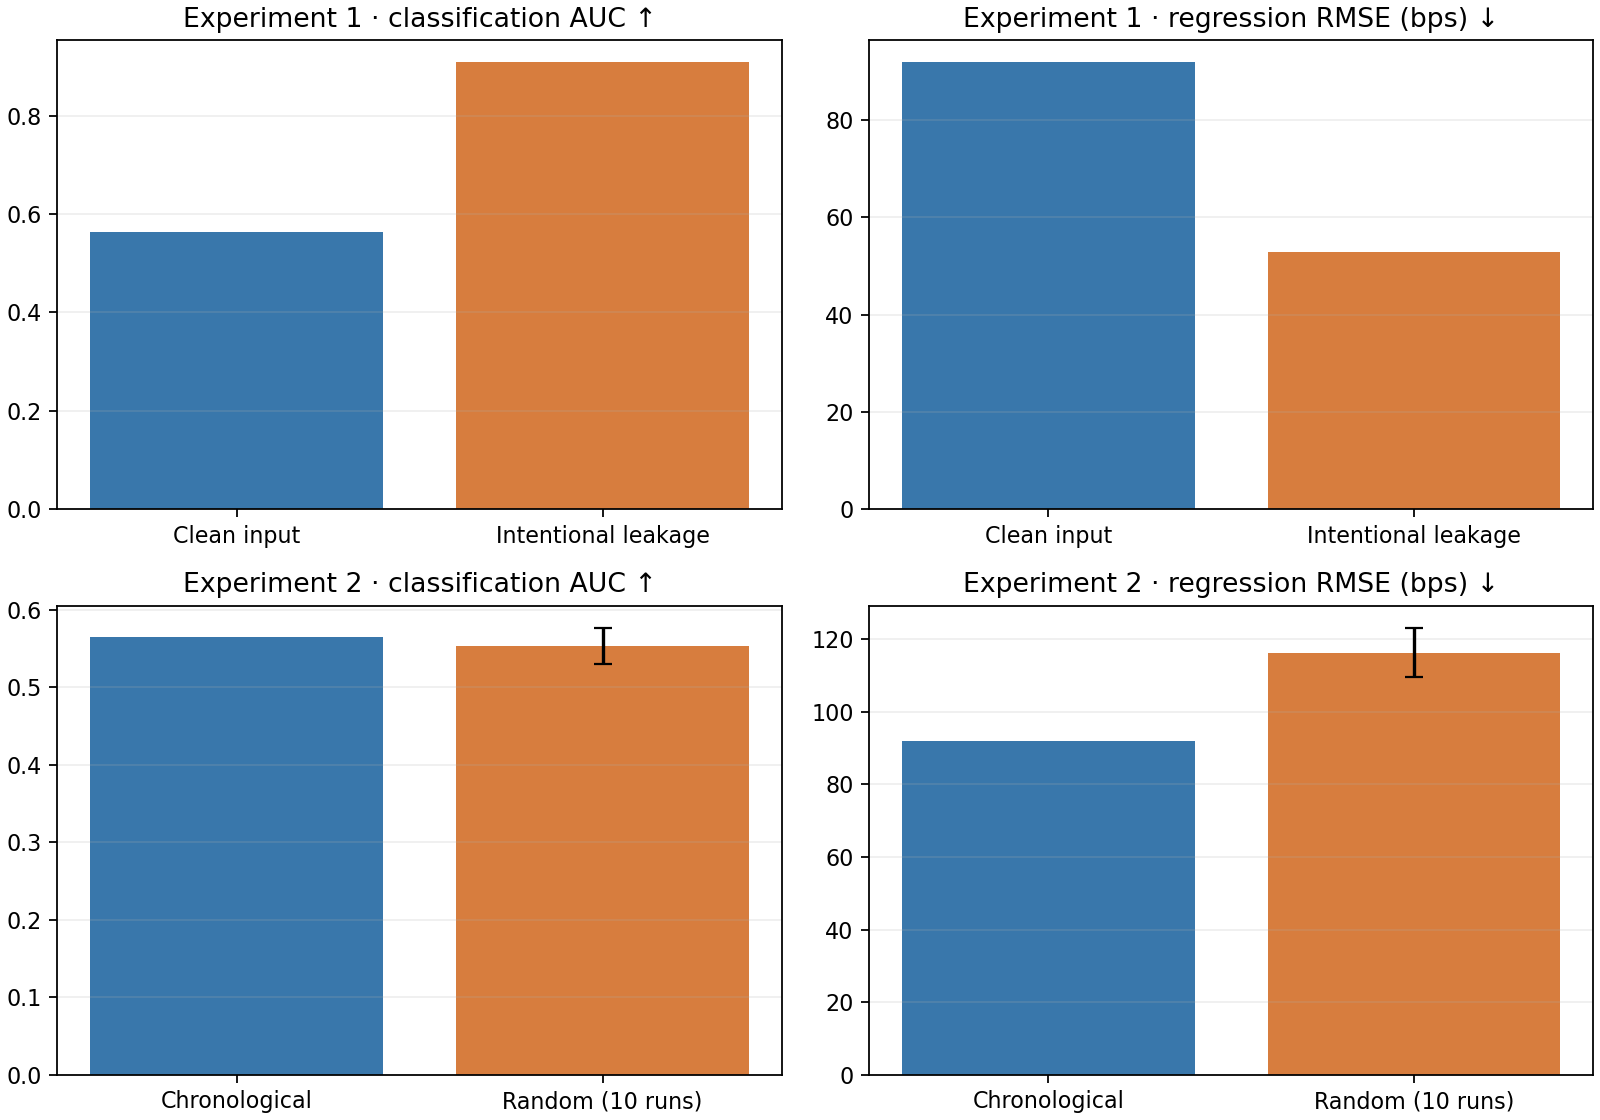

Output directory: output/validation_experiments/20261123_220656_137184


In [21]:
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
def draw_comparison(ax, table, task, metric, conditions, names, title):
    """Plot one task with two experiment arms."""
    means = []
    standard_deviations = []
    sizes = []
    for method, mode in conditions:
        mask = (table["task"] == task) & (table["method"] == method) & (table["feature_mode"] == mode)
        values = table.loc[mask, metric]
        means.append(values.mean())
        sizes.append(len(values))
        standard_deviations.append(values.std(ddof=1))
    ax.bar([0, 1], means, color=["#3977ab", "#d77d3e"])
    if sizes[1] > 1:
        ax.errorbar([1], [means[1]], yerr=[standard_deviations[1]], fmt="none", color="black", capsize=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(names)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.2)

# Create separate plots for each task and experiment.
leak_conditions = [("Chronological", "clean"), ("Chronological", "leak")]
split_conditions = [("Chronological", "clean"), ("Random", "clean")]
draw_comparison(axes[0, 0], experiment1_results, "classification", "roc_auc", leak_conditions,
                ["Clean input", "Intentional leakage"], "Experiment 1 · classification AUC ↑")
draw_comparison(axes[0, 1], experiment1_results, "regression", "rmse_bp", leak_conditions,
                ["Clean input", "Intentional leakage"], "Experiment 1 · regression RMSE (bps) ↓")
draw_comparison(axes[1, 0], experiment2_results, "classification", "roc_auc", split_conditions,
                ["Reused chronological baseline", "Random split (10 runs)"], "Experiment 2 · classification AUC ↑")
draw_comparison(axes[1, 1], experiment2_results, "regression", "rmse_bp", split_conditions,
                ["Reused chronological baseline", "Random split (10 runs)"], "Experiment 2 · regression RMSE (bps) ↓")
fig.savefig(RUN.path / "two_experiments.png", dpi=160)
if get_ipython() is not None:
    from IPython.display import display
    display(fig)
plt.close(fig)
save_json(RUN.path / "status.json", {"status": "completed", "unique_models_trained_and_tested": len(results),
                                    "normal_time_baseline_reused": True, "random_repeats": len(RANDOM_SEEDS)})
print("Output directory:", display_path(RUN.path))


### 解释范围

泄漏组只是错误示例；随机划分还改变了测试行情。参考：[数据泄漏](https://scikit-learn.org/stable/common_pitfalls.html)、[时序划分](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)。


In [ ]:
save_json(RUN.path / "status.json", {"status": "completed", "unique_models": len(results)})